<a href="https://colab.research.google.com/github/M-AKSHAYAA1410/netflix-content-analysis/blob/main/Netflix_Data_Exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
df = pd.read_csv("netflix_titles.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:
# Dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Data types and non-null counts
print("\nDataset information:")
df.info()

Number of rows: 8807
Number of columns: 12

Column names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [ ]:
# Missing values in each column
missing_values = df.isnull().sum()

print("Missing values by column:")
print(missing_values[missing_values > 0].sort_values(ascending=False))

# Duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# Duplicate show IDs
print("Duplicate show IDs:", df["show_id"].duplicated().sum())

Missing values by column:
director      2634
country        831
cast           825
date_added      10
rating           4
duration         3
dtype: int64

Duplicate rows: 0
Duplicate show IDs: 0


In [ ]:
# Create a separate copy for cleaning
df_clean = df.copy()

# Fill missing descriptive information
columns_to_fill = [
    "director",
    "cast",
    "country",
    "rating",
    "duration"
]

for column in columns_to_fill:
    df_clean[column] = df_clean[column].fillna("Unknown")

# Convert date_added into a proper date format
df_clean["date_added"] = pd.to_datetime(
    df_clean["date_added"],
    format="mixed",
    errors="coerce"
)

# Verify the cleaning results
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

print("\nCleaned data preview:")
display(df_clean.head())

Original dataset shape: (8807, 12)
Cleaned dataset shape: (8807, 12)

Missing values after cleaning:
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         0
listed_in        0
description      0
dtype: int64

Cleaned data preview:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:
# Count Movies and TV Shows
content_counts = df_clean["type"].value_counts()

print("Content Type Distribution:")
print(content_counts)

# Calculate percentages using NumPy
content_percentages = (
    np.array(content_counts) / len(df_clean)
) * 100

print("\nContent Type Percentages:")
for content_type, percentage in zip(
    content_counts.index, content_percentages
):
    print(f"{content_type}: {percentage:.2f}%")

Content Type Distribution:
type
Movie      6131
TV Show    2676
Name: count, dtype: int64

Content Type Percentages:
Movie: 69.62%
TV Show: 30.38%


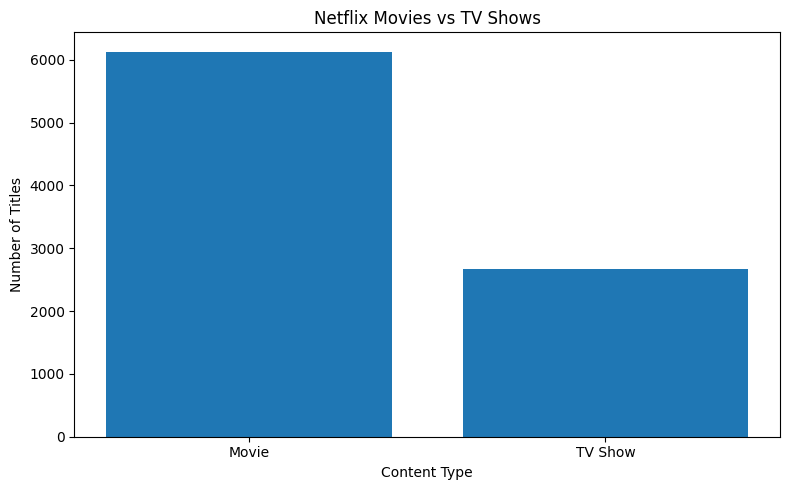

In [ ]:
# Matplotlib visualization
plt.figure(figsize=(8, 5))
plt.bar(content_counts.index, content_counts.values)
plt.title("Netflix Movies vs TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()



### Finding 1: Movies vs TV Shows

The dataset contains 8,807 titles, including 6,131 movies (69.62%) and 2,676 TV shows (30.38%).

**Insight:** Movies account for the larger share of titles in this Netflix catalogue snapshot.

**Business interpretation:** The catalogue has a stronger representation of movies than TV shows. However, this distribution alone does not indicate which content type receives more views or generates more engagement.

In [ ]:
# Split multiple genres into individual rows
genre_data = df_clean[["show_id", "listed_in"]].copy()

genre_data["genre"] = genre_data["listed_in"].str.split(", ")

genre_data = genre_data.explode("genre")

print("Total genre records:", len(genre_data))
print("\nUnique genres:", genre_data["genre"].nunique())

display(genre_data.head(10))

Total genre records: 19323

Unique genres: 42


,show_id,listed_in,genre
0,s1,Documentaries,Documentaries
1,s2,"International TV Shows, TV Dramas, TV Mysteries",International TV Shows
1,s2,"International TV Shows, TV Dramas, TV Mysteries",TV Dramas
1,s2,"International TV Shows, TV Dramas, TV Mysteries",TV Mysteries
2,s3,"Crime TV Shows, International TV Shows, TV Act...",Crime TV Shows
2,s3,"Crime TV Shows, International TV Shows, TV Act...",International TV Shows
2,s3,"Crime TV Shows, International TV Shows, TV Act...",TV Action & Adventure
3,s4,"Docuseries, Reality TV",Docuseries
3,s4,"Docuseries, Reality TV",Reality TV
4,s5,"International TV Shows, Romantic TV Shows, TV ...",International TV Shows


In [ ]:
# Count titles in each genre
genre_counts = (
    genre_data.groupby("genre")["show_id"]
    .nunique()
    .sort_values(ascending=False)
)

top_10_genres = genre_counts.head(10)

print("Top 10 Netflix Genres:")
print(top_10_genres)

Top 10 Netflix Genres:
genre
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: show_id, dtype: int64


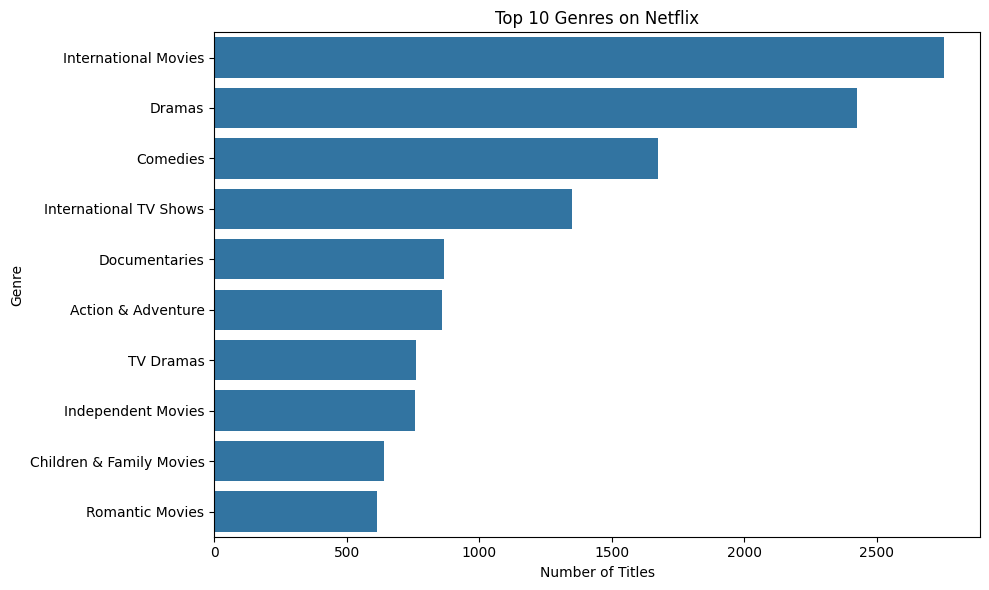

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_10_genres.values,
    y=top_10_genres.index
)

plt.title("Top 10 Genres on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

### Finding 2: Genre Analysis

The genre analysis shows that International Movies is the most frequently listed category, with 2,752 titles, followed by Dramas (2,427) and Comedies (1,674).

**Key insight:** International Movies, Dramas, and Comedies are the three most frequently listed categories in this catalogue.

**Business interpretation:** These categories represent a substantial part of the catalogue's content variety. However, the number of titles does not indicate actual viewing popularity or audience demand.

**Method:** Multiple genre labels were separated into individual rows using Pandas `explode()` and unique titles were counted for each genre.

In [ ]:
# Count titles by release year
release_year_counts = (
    df_clean.groupby("release_year")["show_id"]
    .nunique()
    .sort_index()
)

print("Number of distinct release years:", release_year_counts.index.nunique())

print("\nTop 10 release years by title count:")
print(
    release_year_counts
    .sort_values(ascending=False)
    .head(10)
)

# Focus on 2000 onwards to make the trend easier to read
recent_release_trend = release_year_counts.loc[2000:]

print("\nTitles released from 2000 onwards:", recent_release_trend.sum())

Number of distinct release years: 74

Top 10 release years by title count:
release_year
2018    1147
2017    1032
2019    1030
2020     953
2016     902
2021     592
2015     560
2014     352
2013     288
2012     237
Name: show_id, dtype: int64

Titles released from 2000 onwards: 8282


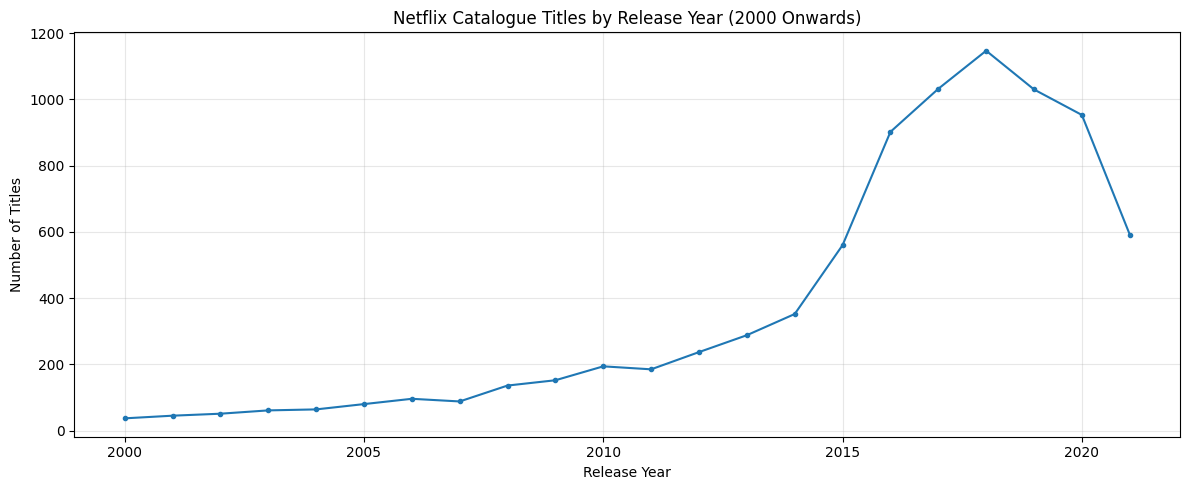

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    recent_release_trend.index,
    recent_release_trend.values,
    marker="o",
    markersize=3
)

plt.title("Netflix Catalogue Titles by Release Year (2000 Onwards)")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Finding 3: Release-Year Trend

The release-year analysis shows that 2018 had the highest number of titles in the dataset, with 1,147 titles. This was followed by 2017 (1,032) and 2019 (1,030).

**Key insight:** The catalogue contains a substantial number of titles released during the late 2010s, with a peak in 2018.

**Business interpretation:** The release-year distribution helps describe the age and recency of content in the catalogue. It does not represent the number of titles added to Netflix each year.

**Method:** Pandas was used to count distinct titles by release year and Matplotlib was used to visualize the trend from 2000 onwards.

In [ ]:
# Select the required columns
country_data = df_clean[["show_id", "country"]].copy()

# Exclude unknown country information from country rankings
country_data = country_data[
    country_data["country"] != "Unknown"
].copy()

# Split titles associated with multiple countries
country_data["country"] = country_data["country"].str.split(", ")

# Create one row per title-country combination
country_data = country_data.explode("country")

# Count distinct titles for each country
country_counts = (
    country_data.groupby("country")["show_id"]
    .nunique()
    .sort_values(ascending=False)
)

top_10_countries = country_counts.head(10)

print("Top 10 Countries by Number of Titles:")
print(top_10_countries)

Top 10 Countries by Number of Titles:
country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: show_id, dtype: int64


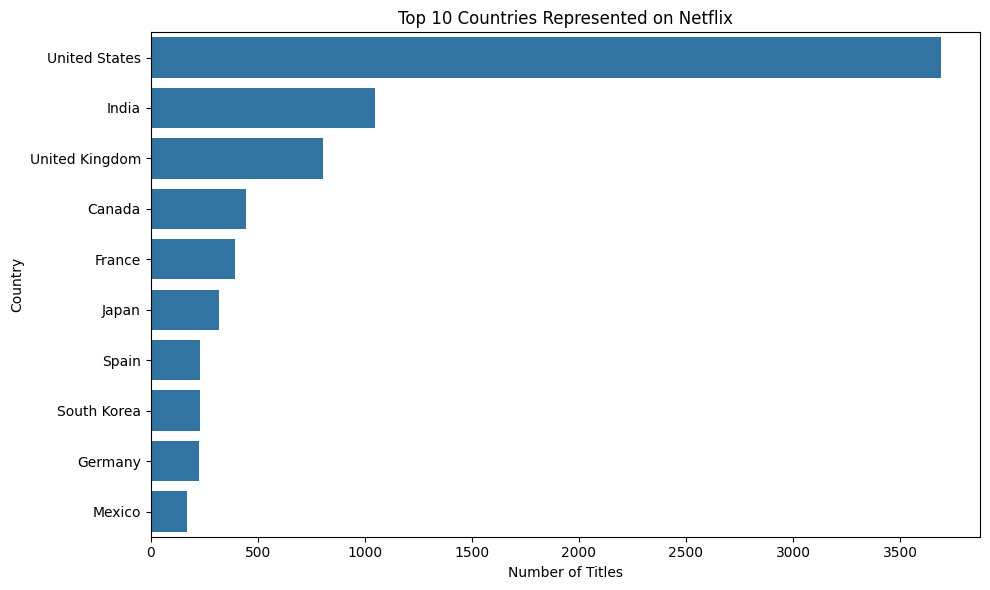

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_10_countries.values,
    y=top_10_countries.index
)

plt.title("Top 10 Countries Represented on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

### Finding 4: Country-wise Content Analysis

The United States has the highest representation in the dataset, with 3,689 titles, followed by India (1,046) and the United Kingdom (804).

**Key insight:** The United States accounts for the largest number of title-country associations among the countries analyzed.

**Business interpretation:** The country distribution describes the geographical representation of titles in the catalogue. Because titles may be associated with multiple countries, these counts are not mutually exclusive.

**Method:** The country field was split into individual country entries and Pandas was used to count distinct titles associated with each country. Seaborn was used to visualize the top 10 countries.

In [ ]:
# Count titles by content rating
rating_counts = (
    df_clean.groupby("rating")["show_id"]
    .nunique()
    .sort_values(ascending=False)
)

top_10_ratings = rating_counts.head(10)

print("Content Rating Distribution:")
print(rating_counts)

print("\nTop 10 Ratings:")
print(top_10_ratings)

Content Rating Distribution:
rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
Unknown        4
NC-17          3
UR             3
66 min         1
74 min         1
84 min         1
Name: show_id, dtype: int64

Top 10 Ratings:
rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
TV-Y7     334
TV-Y      307
PG        287
TV-G      220
NR         80
Name: show_id, dtype: int64


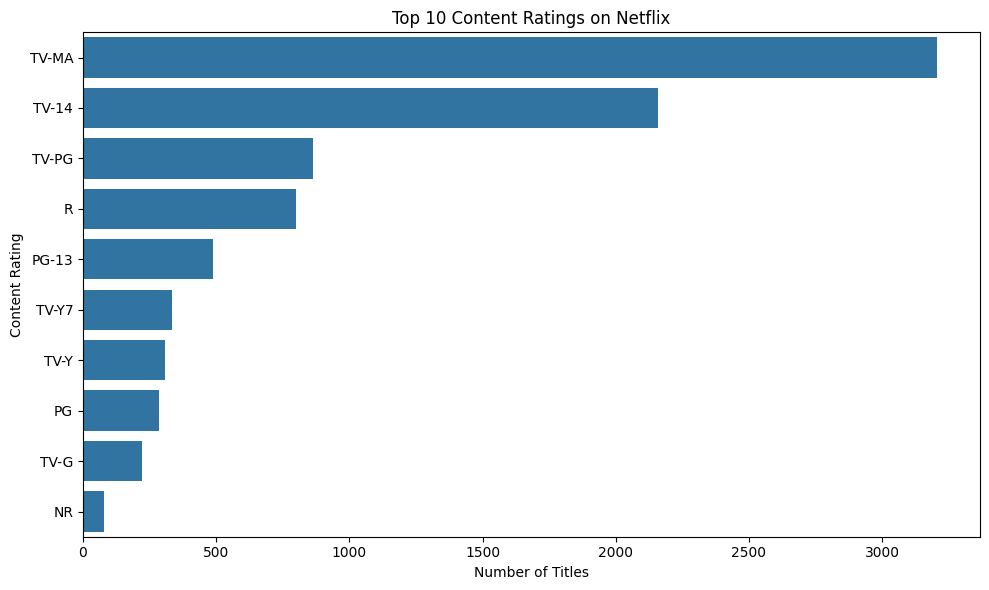

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_10_ratings.values,
    y=top_10_ratings.index
)

plt.title("Top 10 Content Ratings on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Content Rating")
plt.tight_layout()
plt.show()

In [ ]:
# Identify duration values mistakenly stored as ratings
invalid_rating_mask = df_clean["rating"].str.match(
    r"^\d+\s*min$", na=False
)

print("Incorrect rating entries found:")
display(
    df_clean.loc[
        invalid_rating_mask,
        ["title", "type", "rating", "duration"]
    ]
)

# Move the duration to the correct column
df_clean.loc[invalid_rating_mask, "duration"] = (
    df_clean.loc[invalid_rating_mask, "rating"]
)

# Mark the actual rating as unknown
df_clean.loc[invalid_rating_mask, "rating"] = "Unknown"

# Verify the correction
print("\nCorrected records:")
display(
    df_clean.loc[
        invalid_rating_mask,
        ["title", "type", "rating", "duration"]
    ]
)

print(
    "\nRemaining duration-like ratings:",
    df_clean["rating"].str.match(
        r"^\d+\s*min$", na=False
    ).sum()
)

Incorrect rating entries found:


,title,type,rating,duration
5541,Louis C.K. 2017,Movie,74 min,Unknown
5794,Louis C.K.: Hilarious,Movie,84 min,Unknown
5813,Louis C.K.: Live at the Comedy Store,Movie,66 min,Unknown



Corrected records:


,title,type,rating,duration
5541,Louis C.K. 2017,Movie,Unknown,74 min
5794,Louis C.K.: Hilarious,Movie,Unknown,84 min
5813,Louis C.K.: Live at the Comedy Store,Movie,Unknown,66 min



Remaining duration-like ratings: 0


In [ ]:
rating_counts = (
    df_clean.groupby("rating")["show_id"]
    .nunique()
    .sort_values(ascending=False)
)

print(rating_counts.head(10))

rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
TV-Y7     334
TV-Y      307
PG        287
TV-G      220
NR         80
Name: show_id, dtype: int64


### Finding 5: Content Rating Analysis

TV-MA is the most frequently recorded content rating, followed by TV-14 and TV-PG.

**Key insight:** TV-MA and TV-14 account for a substantial share of the catalogue's recorded ratings.

**Data quality improvement:** Three duration values were incorrectly stored in the rating column. These values were moved to the duration column, and their ratings were marked as Unknown.

**Business interpretation:** Rating categories describe content classification, not viewing popularity. Different rating systems should not be treated as directly equivalent age levels.

### Data Quality Issue: Incorrect Rating Values

During data validation, three movie durations (74 min, 84 min, and 66 min) were found incorrectly recorded in the rating column.

**Correction performed:**
- Moved the three duration values to the `duration` column.
- Replaced the invalid rating values with `Unknown`.
- Verified that no duration-like values remain in the rating column.

**Result:** The affected records now have a more consistent structure, improving the reliability of rating-based analysis.

In [ ]:
# Save the cleaned dataset
output_file = "netflix_cleaned.csv"

df_clean.to_csv(output_file, index=False)

print("Cleaned dataset saved successfully:", output_file)
print("Final dataset shape:", df_clean.shape)
print("Remaining missing values:", df_clean.isnull().sum().sum())

Cleaned dataset saved successfully: netflix_cleaned.csv
Final dataset shape: (8807, 12)
Remaining missing values: 10


In [ ]:
from google.colab import files
files.download("netflix_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
df_clean = pd.read_csv(
    "netflix_cleaned.csv",
    parse_dates=["date_added"]
)

print("Cleaned dataset loaded!")
print("Shape:", df_clean.shape)

display(df_clean.head())

Cleaned dataset loaded!
Shape: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:
# Extract the year each title was added
df_clean["year_added"] = df_clean["date_added"].dt.year

# Count titles added in each year
added_year_counts = (
    df_clean.dropna(subset=["year_added"])
    .groupby("year_added")["show_id"]
    .nunique()
    .sort_index()
)

print("Titles added to Netflix by year:")
print(added_year_counts)

print("\nTop 10 years by titles added:")
print(
    added_year_counts
    .sort_values(ascending=False)
    .head(10)
)

print(
    "\nRecords excluded due to missing dates:",
    df_clean["date_added"].isna().sum()
)

Titles added to Netflix by year:
year_added
2008.0       2
2009.0       2
2010.0       1
2011.0      13
2012.0       3
2013.0      11
2014.0      24
2015.0      82
2016.0     429
2017.0    1188
2018.0    1649
2019.0    2016
2020.0    1879
2021.0    1498
Name: show_id, dtype: int64

Top 10 years by titles added:
year_added
2019.0    2016
2020.0    1879
2018.0    1649
2021.0    1498
2017.0    1188
2016.0     429
2015.0      82
2014.0      24
2011.0      13
2013.0      11
Name: show_id, dtype: int64

Records excluded due to missing dates: 10


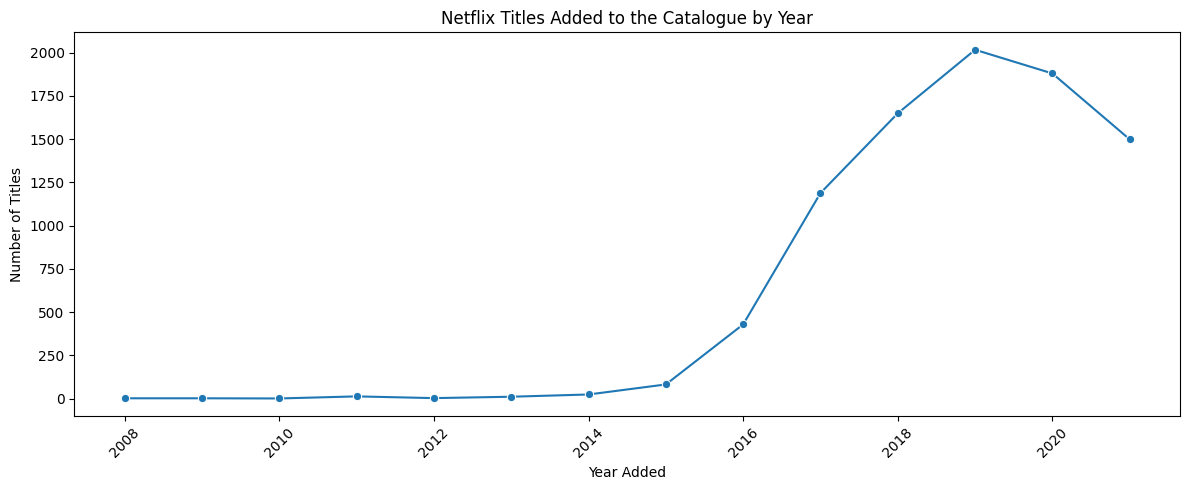

In [ ]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    x=added_year_counts.index,
    y=added_year_counts.values,
    marker="o"
)

plt.title("Netflix Titles Added to the Catalogue by Year")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Finding 6: Netflix Catalogue Additions by Year

The dataset records the highest number of titles added in 2019, with 2,016 titles, followed by 2020 (1,879) and 2018 (1,649).

**Key insight:** Recorded catalogue additions increased sharply between 2016 and 2019, peaked in 2019 and then declined through 2021.

**Business interpretation:** This trend describes the addition dates available in this dataset snapshot. It should not be interpreted as a complete historical record of Netflix's global content additions.

**Method:** Pandas was used to extract the year from `date_added` and count distinct titles. Seaborn was used to visualize the yearly trend. Ten records with missing addition dates were excluded from this analysis.

In [ ]:
df_clean.to_csv("netflix_cleaned.csv", index=False)

print("Updated dataset saved successfully!")
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])
print("Columns included:", df_clean.columns.tolist())

Updated dataset saved successfully!
Rows: 8807
Columns: 13
Columns included: ['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description', 'year_added']
